# PISA Example Using Public IceCube Data


Dataset must be obtained from the PRD 2023 paper of IceCube

https://dataverse.harvard.edu/dataset.xhtml?persistentId=doi:10.7910/DVN/B4RITM&version=1.0

## Setup

Usually you would need to export the location of the data, and the config files to `PISA_RESOURCES`. For this example however, the data is inside our package.

In [1]:
import numpy as np
from uncertainties import unumpy as unp
import matplotlib.pyplot as plt
import copy
import os
import pisa
from pisa.core.distribution_maker import DistributionMaker
from pisa.core.pipeline import Pipeline
from pisa.analysis.analysis import Analysis
from pisa import FTYPE, ureg

<< PISA is running in double precision (FP64) mode; numba is running on CPU (single core) >>


In [2]:
fridge_path = '/home/jp/icecube/wg-oscillations-fridge/analysis'

In [3]:
os.environ['PISA_RESOURCES'] = fridge_path

In [4]:
myfiles_path = '/home/jp/daemonflux/oscillations_release_2023'

In [5]:
## Model

We can now instantiate the `model` (given our configs) that we later fit to data. This now containes two `Pipelines` in a `DistributionMaker`, one for our neutrinos, and one for the background muons.

In [8]:
model = DistributionMaker([
    os.path.join(myfiles_path,"pisa_settings/pipeline/neutrino_pipeline_daemon.cfg"),
    os.path.join(myfiles_path,"pisa_settings/pipeline/muon_pipeline.cfg")
])

[ WARNING] /home/jp/anaconda3/envs/pisa/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")

Calibration file None
[ WARNING] /home/jp/anaconda3/envs/pisa/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")



In [ ]:
## Verifying that there are things loaded
#model.pipelines[0].data['numu_cc']['true_energy']
#model.pipelines[1].data['icc']['reco_energy']
#model.pipelines[2].data['total']['reco_energy']

In [ ]:
# Confirming that the data has been loaded
loader = model.pipelines[0]
loader

Our model has a number of free parameters, that will be used in our fit to the data

In [9]:
model.params.free

name,value,nominal_value,range,prior,units,is_fixed
daemon_K_158G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_K_2P,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_K_31G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_158G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_2P,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_31G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_n_158G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_n_2P,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_p_158G,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_p_2P,0,0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False


The two pipelines are quite different, with most complexity in the neutrino pipeline, that has several `Stage`s and free parameters:

In [10]:
model.pipelines[0].stages[1].params

name,value,nominal_value,range,prior,units,is_fixed
daemon_K_158G,0,0,"[-3.0, 3.0]",+/- 1.0,1,False
daemon_K_2P,0,0,"[-3.0, 3.0]",+/- 1.0,1,False
daemon_K_31G,0,0,"[-3.0, 3.0]",+/- 1.0,1,False
daemon_antiK_158G,0,0,"[-3.0, 3.0]",+/- 1.0,1,False
daemon_antiK_2P,0,0,"[-3.0, 3.0]",+/- 1.0,1,False
daemon_antiK_31G,0,0,"[-3.0, 3.0]",+/- 1.0,1,False
daemon_n_158G,0,0,"[-3.0, 3.0]",+/- 1.0,1,False
daemon_n_2P,0,0,"[-3.0, 3.0]",+/- 1.0,1,False
daemon_p_158G,0,0,"[-3.0, 3.0]",+/- 1.0,1,False
daemon_p_2P,0,0,"[-3.0, 3.0]",+/- 1.0,1,False


While the muon pipleine is rather simple

## Get data

In [11]:
# real data
data_maker = Pipeline(os.path.join(myfiles_path,"pisa_settings/pipeline/data_pipeline.cfg"))
data = data_maker.get_outputs()

## Fitting

For fitting we need to configure a minimizer, several standard cfgs are available, but you can also define your own.
For the fit we need to choose a `metric`, and by default, theta23 octants, which are quasi degenerate, are fit seperately, which means two fits are run.

In [12]:
local_fit_minuit = {
    "method": "iminuit",
    "method_kwargs": {
        "errors": 0.1,
        "precision": 1e-14,  # default: double precision
        "tol": 1e-2,  # default: 0.1
        "run_simplex": False,
        "run_migrad": True
    },
    "local_fit_kwargs": None
}

In [13]:
fit_octant = {
    "method": "octants",
    "method_kwargs": {
        "angle": "theta23",
        "inflection_point": 45 * ureg.degrees,
    },
    "local_fit_kwargs": local_fit_minuit
}

In [14]:
ana = Analysis()
ana.pprint=False

In [15]:
result = ana.fit_recursively(
    data_dist=data,
    hypo_maker=model,
    metric='chi2',
    external_priors_penalty=None,
    **fit_octant,
)

[ WARNING] /home/jp/software/pisa/pisa/stages/flux/daemon_flux.py:166: NumbaWarning: 
Compilation is falling back to object mode WITHOUT looplifting enabled because Function "make_2d_flux_map" failed type inference due to: non-precise type pyobject
During: typing of argument at /home/jp/software/pisa/pisa/stages/flux/daemon_flux.py (181)

File "../pisa/stages/flux/daemon_flux.py", line 181:
def make_2d_flux_map(flux_obj,
    <source elided>

    for index in range(len(icangles)):
    ^

  @jit(forceobj=True)



Here we can view the bestfit parameters - the result of our fit.
We have run two fits (separately for each theta23 octant), and the best result is stored in `results[0]` (both fits are also available under `results[1]`)

In [16]:
result.metric_val

207.07731845963644

In [17]:
result.params

name,value,nominal_value,range,prior,units,is_fixed
daemon_K_158G,0.28387496844404403,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_K_2P,1.4717178192051978,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_K_31G,-0.14387231191574923,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_158G,0.03483063744578274,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_2P,1.4829226304647776,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_antiK_31G,-0.0204490733919096,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_n_158G,-0.03309522990756575,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_n_2P,0.028283112458776127,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_p_158G,0.021115776213336712,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False
daemon_p_2P,0.06369938751522763,0.0,"[-3.0, 3.0]",+/- 1.0,dimensionless,False


In [30]:
print(np.sin(np.deg2rad(result['params']['theta23'].value))**2, "||| 0.51+/-0.05")
print((result['params']['deltam31'].value-result['params']['deltam21'].value)*1E3, "||| 2.41+/-0.07")

0.5154561927618274 dimensionless ||| 0.51+/-0.05
2.383499680146845 electron_volt ** 2 ||| 2.41+/-0.07


In [19]:
# Copy parameters and update the model 

bestfit_params = result['params'].free
model.update_params(copy.deepcopy(bestfit_params))


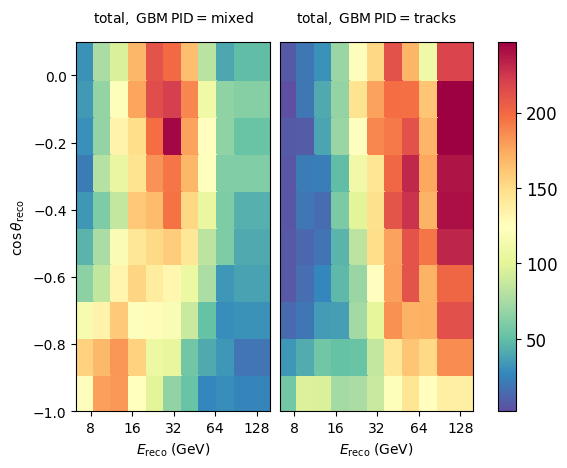

In [20]:
data.plot()

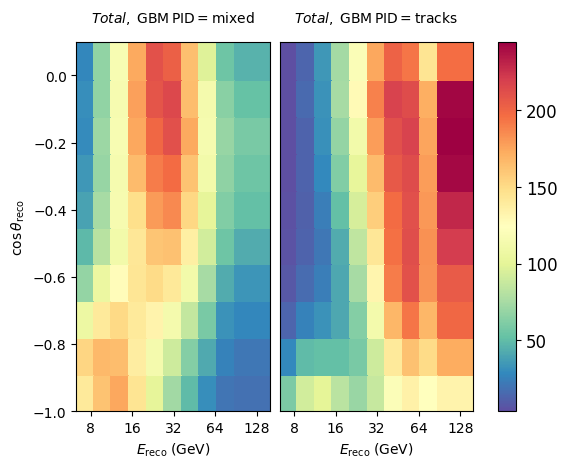

In [21]:
template = model.get_outputs(return_sum=True)
template.plot()

Let's see how good that fit looks like. We here construct signed mod_chi2 maps by hand.
You can see that after the fit, it improved considerably, and the distribution of chi2 values is now more uniform - not much features can be seen anymore.

Evaluating other metrics just for fun:

In [23]:
for metric in pisa.utils.stats.ALL_METRICS:
    try:
        print('%s = %.3f'%(metric,data.metric_total(bestfit, metric)))
    except:
        print('%s failed'%metric)

llh = -101.610
conv_llh = -100.884
barlow_llh = -1853.630
mcllh_mean = -725.637
mcllh_eff = -725.611
generalized_poisson_llh failed
chi2 = 203.356
mod_chi2 = 201.841
[ WARNING] /home/jp/anaconda3/envs/pisa/lib/python3.10/site-packages/numpy/core/_methods.py:114: FutureWarning: AffineScalarFunc.__ge__() is deprecated. It will be removed in a future release.
  return ufunc(*args, out=out, **kwargs)

[ WARNING] /home/jp/anaconda3/envs/pisa/lib/python3.10/site-packages/numpy/core/_methods.py:114: FutureWarning: AffineScalarFunc.__le__() is deprecated. It will be removed in a future release.
  return ufunc(*args, out=out, **kwargs)

correct_chi2 = 1083.752
weighted_chi2 failed


Adding prior penalty terms

## Storing the results to a file

Since the fit took a while, it might be useful to store the results to a file. (NB: in this example we use a temp file, but in real life you would of course just use a real pathname instead!)

In [24]:
outdir = '/home/jp/daemonflux/oscillations_release_2023/pisa_results/'
filename = 'pfix_daemonflux_full.json'
pisa.utils.fileio.to_file(result, outdir+filename)

[ WARNING] Directory "/home/jp/daemonflux/oscillations_release_2023/pisa_results" already exists


To reload, we can read the file. But to get PISA objects back, they need to instantiated

In [ ]:
result_reload = pisa.utils.fileio.from_file(temp.name)
bestfit_params = pisa.core.ParamSet(result_reload['params']).free
bestfit_params
temp.close()